# MarketMind — Experiment 4: Dual-Scale Temporal Learning

**Goal:** Test whether separating market behaviour into low-frequency and high-frequency wavelet features improves regime discovery, and whether combining both scales with conventional OHLC features adds value.

This experiment compares five feature sets:

1. **Baseline OHLC:** six conventional features used in the earlier HMM experiment.
2. **Wavelet low-frequency:** three trend-like wavelet summaries.
3. **Wavelet high-frequency:** five detail/energy summaries.
4. **Wavelet dual-scale:** low- and high-frequency features combined.
5. **Baseline + dual-scale:** conventional OHLC features combined with all wavelet features.

Each feature set is evaluated with K-Means, Gaussian Mixture Model (GMM), and a 4-state Gaussian HMM. The chronological 70/30 split is shared across all experiments.

### Methodological safeguards
- The wavelet features are loaded from Experiment 3's causal trailing-window output.
- The OHLC features use only current and past observations.
- Scalers are fitted on training data only.
- HMM sequences reset at each trading session; overnight gaps are not treated as ordinary transitions.
- HMM test states are assigned using forward-filtered probabilities, not smoothed posteriors.
- There are no independent ground-truth regime labels. Silhouette, Davies–Bouldin and Calinski–Harabasz are internal diagnostics, not classification accuracy.
- No profitability claim is made. Strategy testing with transaction costs and slippage remains a separate step.

## 0. Install dependencies
Run this cell once. Restart the kernel if new packages were installed.

In [1]:
%pip install -q numpy pandas matplotlib scikit-learn hmmlearn scipy

Note: you may need to restart the kernel to use updated packages.


## 1. Imports and automatic project-folder detection

In [2]:
from pathlib import Path
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from hmmlearn.hmm import GaussianHMM
from scipy.special import logsumexp

RANDOM_STATE = 42
TRAIN_FRACTION = 0.70
HMM_STATES = 4
HMM_MAX_ITER = 120
MAX_HMM_TRAIN_ROWS = 20000
MAX_HMM_TEST_ROWS = 10000
METRIC_SAMPLE_SIZE = 6000

cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, *cwd.parents]
             if (p / "data" / "raw" / "nifty50" / "1min").is_dir()), None)
if ROOT is None:
    for p in [cwd, *cwd.parents]:
        candidate = p / "MarketMind"
        if (candidate / "data" / "raw" / "nifty50" / "1min").is_dir():
            ROOT = candidate
            break
if ROOT is None:
    raise FileNotFoundError(
        "Could not locate MarketMind/data/raw/nifty50/1min. "
        f"Current working directory: {cwd}. Keep this notebook in MarketMind/research."
    )

DATA_DIR = ROOT / "data" / "raw" / "nifty50" / "1min"
WAVELET_DIR = ROOT / "research" / "wavelet_results"
OUT_DIR = ROOT / "research" / "dual_scale_results"
OUT_DIR.mkdir(parents=True, exist_ok=True)

WAVELET_FILE = WAVELET_DIR / "causal_wavelet_features.csv"
if not WAVELET_FILE.exists():
    raise FileNotFoundError(
        f"Missing {WAVELET_FILE}. Run Experiment 3 (causal wavelet notebook) first."
    )

print("Project root:", ROOT)
print("Wavelet feature file:", WAVELET_FILE)
print("Output folder:", OUT_DIR)

Project root: D:\College_Stuff\Sem_5\Machine_Learning\CP\final\2\MarketMind
Wavelet feature file: D:\College_Stuff\Sem_5\Machine_Learning\CP\final\2\MarketMind\research\wavelet_results\causal_wavelet_features.csv
Output folder: D:\College_Stuff\Sem_5\Machine_Learning\CP\final\2\MarketMind\research\dual_scale_results


## 2. Load and validate the NIFTY 50 one-minute data

In [3]:
files = sorted(DATA_DIR.rglob("*.csv"))
if not files:
    raise FileNotFoundError(f"No 1-minute CSV files found under {DATA_DIR}")

required = ["Timestamp", "Open", "High", "Low", "Close"]
frames, file_audit = [], []

for path in files:
    df = pd.read_csv(path)
    if not set(required).issubset(df.columns):
        continue
    df = df[required].copy()
    df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")
    for col in ["Open", "High", "Low", "Close"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    frames.append(df)
    file_audit.append({
        "file": str(path.relative_to(ROOT)),
        "rows": len(df),
        "start": str(df["Timestamp"].min()),
        "end": str(df["Timestamp"].max())
    })

if not frames:
    raise ValueError("No CSV files with Timestamp, Open, High, Low, Close were found.")

raw = pd.concat(frames, ignore_index=True).sort_values("Timestamp")
raw = raw.dropna(subset=required).drop_duplicates("Timestamp", keep="first")
raw = raw[(raw[["Open", "High", "Low", "Close"]] > 0).all(axis=1)]
raw = raw[raw["High"] >= raw[["Open", "Close", "Low"]].max(axis=1)]
raw = raw[raw["Low"] <= raw[["Open", "Close", "High"]].min(axis=1)]
raw = raw.set_index("Timestamp").sort_index().between_time("09:15", "15:29").copy()
raw["session_date"] = raw.index.date

def resample_session(day):
    day = day.drop(columns=["session_date"])
    return day.resample(
        "15min", origin="start_day", offset="9h15min",
        label="left", closed="left"
    ).agg({
        "Open": "first", "High": "max", "Low": "min", "Close": "last"
    }).dropna(subset=["Open", "High", "Low", "Close"])

bars = pd.concat(
    [resample_session(g) for _, g in raw.groupby("session_date")],
).sort_index()
bars = bars[
    (bars.index.time >= pd.Timestamp("09:15").time()) &
    (bars.index.time <= pd.Timestamp("15:15").time())
]

print(f"Loaded {len(files)} CSV files; cleaned 1-minute rows: {len(raw):,}")
print(f"15-minute bars: {len(bars):,}")
print("Coverage:", bars.index.min(), "to", bars.index.max())
display(pd.DataFrame(file_audit).head())

Loaded 20 CSV files; cleaned 1-minute rows: 890,607
15-minute bars: 59,378
Coverage: 2017-04-03 09:15:00 to 2026-11-17 15:15:00


,file,rows,start,end
0,data\raw\nifty50\1min\2017\NIFTY50_1min_2017.csv,69375,2017-04-03 09:15:00,2017-12-29 15:29:00
1,data\raw\nifty50\1min\2018\NIFTY50_1min_2018.csv,91874,2018-01-01 09:15:00,2018-12-31 15:29:00
2,data\raw\nifty50\1min\2019\NIFTY50_1min_2019.csv,91500,2019-01-01 09:15:00,2019-12-31 15:29:00
3,data\raw\nifty50\1min\2020\NIFTY50_1min_2020.csv,94125,2020-01-01 09:15:00,2020-12-31 15:29:00
4,data\raw\nifty50\1min\2021\NIFTY50_1min_2021.csv,92668,2021-01-01 09:15:00,2021-12-31 15:29:00


## 3. Rebuild the six baseline OHLC features
These features are calculated using current and past data only. Rolling windows are trailing, not centered.

In [4]:
close = bars["Close"]
prev_close = close.shift(1)
log_ret = np.log(close).diff()
delta = close.diff()

gain = delta.clip(lower=0).rolling(14, min_periods=14).mean()
loss = (-delta.clip(upper=0)).rolling(14, min_periods=14).mean()
rs = gain / loss.replace(0, np.nan)
rsi = 100 - (100 / (1 + rs))

true_range = pd.concat([
    bars["High"] - bars["Low"],
    (bars["High"] - prev_close).abs(),
    (bars["Low"] - prev_close).abs()
], axis=1).max(axis=1)
atr = true_range.rolling(14, min_periods=14).mean()

baseline = pd.DataFrame(index=bars.index)
baseline["ret_5"] = np.log(close).diff(5) * 100
baseline["roll_vol"] = log_ret.rolling(20, min_periods=20).std() * 100
baseline["rsi"] = rsi
baseline["ma_diff"] = (close.rolling(20).mean() / close.rolling(50).mean() - 1) * 100
baseline["momentum"] = (close / close.shift(10) - 1) * 100
baseline["atr_pct"] = atr / close * 100
baseline = baseline.replace([np.inf, -np.inf], np.nan).dropna()

print("Baseline features:", list(baseline.columns))
display(baseline.describe().T)

Baseline features: ['ret_5', 'roll_vol', 'rsi', 'ma_diff', 'momentum', 'atr_pct']


,count,mean,std,min,25%,50%,75%,max
ret_5,59313.0,0.008375,0.450660,-11.497840,-0.152845,0.013180,0.174330,11.262615
roll_vol,59313.0,0.154018,0.127837,0.023405,0.091404,0.125586,0.178297,3.130192
rsi,59313.0,51.790650,19.132641,0.000000,37.471474,51.765376,66.362091,99.928622
ma_diff,59313.0,0.025616,0.501057,-5.031037,-0.219457,0.044475,0.289268,4.442814
momentum,59313.0,0.018783,0.637106,-12.380133,-0.240887,0.027888,0.288670,14.272556
atr_pct,59313.0,0.202110,0.127923,0.053371,0.133113,0.174461,0.233717,2.724547


## 4. Load Experiment 3 wavelet features and define feature groups
The notebook does not recompute the wavelet transform. It uses the causal trailing-window features produced by Experiment 3.

In [5]:
wavelet = pd.read_csv(WAVELET_FILE, parse_dates=["Timestamp"], index_col="Timestamp")
wavelet = wavelet.sort_index()
wavelet = wavelet[~wavelet.index.duplicated(keep="first")]

low_cols = [
    "wavelet_low_last",
    "wavelet_low_mean",
    "wavelet_low_slope"
]
high_cols = [
    "wavelet_detail_d3_energy",
    "wavelet_detail_d2_energy",
    "wavelet_detail_d1_energy",
    "wavelet_high_energy",
    "wavelet_high_low_ratio"
]
missing_wavelet = [c for c in low_cols + high_cols if c not in wavelet.columns]
if missing_wavelet:
    raise ValueError(f"Wavelet output is missing expected columns: {missing_wavelet}")

# The ratio can have extreme values when the low-frequency denominator is near zero.
# log1p preserves non-negativity while compressing the long right tail.
wavelet_model = wavelet[low_cols + high_cols].copy()
wavelet_model["wavelet_high_low_ratio"] = np.log1p(
    wavelet_model["wavelet_high_low_ratio"].clip(lower=0)
)
wavelet_model = wavelet_model.replace([np.inf, -np.inf], np.nan)

print("Wavelet rows:", len(wavelet_model))
print("Low-frequency features:", low_cols)
print("High-frequency features:", high_cols)

Wavelet rows: 21366
Low-frequency features: ['wavelet_low_last', 'wavelet_low_mean', 'wavelet_low_slope']
High-frequency features: ['wavelet_detail_d3_energy', 'wavelet_detail_d2_energy', 'wavelet_detail_d1_energy', 'wavelet_high_energy', 'wavelet_high_low_ratio']


## 5. Align datasets and create identical chronological partitions
All model variants use exactly the same timestamps. This is essential for a fair comparison.

In [6]:
common_index = baseline.index.intersection(wavelet_model.index).sort_values()
data = pd.concat([
    baseline.loc[common_index].add_prefix("base__"),
    wavelet_model.loc[common_index]
], axis=1).replace([np.inf, -np.inf], np.nan).dropna()

BASE_COLS = [f"base__{c}" for c in baseline.columns]
LOW_COLS = low_cols
HIGH_COLS = high_cols
DUAL_COLS = LOW_COLS + HIGH_COLS
BASE_DUAL_COLS = BASE_COLS + DUAL_COLS

feature_sets = {
    "baseline_ohlc": BASE_COLS,
    "wavelet_low_only": LOW_COLS,
    "wavelet_high_only": HIGH_COLS,
    "wavelet_dual_scale": DUAL_COLS,
    "baseline_plus_dual_scale": BASE_DUAL_COLS
}

split_at = int(len(data) * TRAIN_FRACTION)
train_all = data.iloc[:split_at].copy()
test_all = data.iloc[split_at:].copy()

print("Aligned observations:", len(data))
print("Train:", len(train_all), "| Test:", len(test_all))
print("Train range:", train_all.index.min(), "to", train_all.index.max())
print("Test range:", test_all.index.min(), "to", test_all.index.max())
print("Feature-set dimensions:", {k: len(v) for k, v in feature_sets.items()})
display(pd.DataFrame([
    {"feature_set": name, "n_features": len(cols)}
    for name, cols in feature_sets.items()
]))

Aligned observations: 21340
Train: 14937 | Test: 6403
Train range: 2017-04-05 15:15:00 to 2023-12-28 14:15:00
Test range: 2023-12-28 14:30:00 to 2026-11-17 15:15:00
Feature-set dimensions: {'baseline_ohlc': 6, 'wavelet_low_only': 3, 'wavelet_high_only': 5, 'wavelet_dual_scale': 8, 'baseline_plus_dual_scale': 14}


,feature_set,n_features
0,baseline_ohlc,6
1,wavelet_low_only,3
2,wavelet_high_only,5
3,wavelet_dual_scale,8
4,baseline_plus_dual_scale,14


## 6. Evaluation helpers
K-Means and GMM produce cluster assignments. HMM produces causal filtered state assignments. Internal cluster metrics are computed on a bounded sample of the held-out observations; they are descriptive diagnostics, not accuracy.

In [7]:
def causal_forward_filter(model, X, lengths):
    """Compute P(state_t | observations up to t), resetting at each session."""
    X = np.asarray(X, dtype=float)
    log_emission = model._compute_log_likelihood(X)
    log_trans = np.log(np.clip(model.transmat_, 1e-300, 1.0))
    filtered = np.empty((len(X), model.n_components), dtype=float)
    offset = 0

    for seq_len in lengths:
        stop = offset + int(seq_len)
        if seq_len <= 0:
            continue
        log_alpha = np.log(np.clip(model.startprob_, 1e-300, 1.0)) + log_emission[offset]
        log_alpha -= logsumexp(log_alpha)
        filtered[offset] = np.exp(log_alpha)

        for t in range(offset + 1, stop):
            log_alpha = log_emission[t] + logsumexp(
                log_alpha[:, None] + log_trans, axis=0
            )
            log_alpha -= logsumexp(log_alpha)
            filtered[t] = np.exp(log_alpha)
        offset = stop

    if offset != len(X):
        raise ValueError("Sequence lengths do not sum to the number of rows.")
    return filtered

def session_lengths(index):
    return pd.Series(1, index=index).groupby(index.date).sum().astype(int).tolist()

def safe_internal_metrics(X, labels):
    X = np.asarray(X)
    labels = np.asarray(labels)
    unique, counts = np.unique(labels, return_counts=True)
    if len(unique) < 2 or len(unique) >= len(labels):
        return {"silhouette": np.nan, "davies_bouldin": np.nan,
                "calinski_harabasz": np.nan}
    return {
        "silhouette": float(silhouette_score(X, labels)),
        "davies_bouldin": float(davies_bouldin_score(X, labels)),
        "calinski_harabasz": float(calinski_harabasz_score(X, labels))
    }

def persistence_without_overnight(states, index):
    s = pd.Series(np.asarray(states), index=index)
    delta = s.index.to_series().diff()
    within = delta <= pd.Timedelta(minutes=30)
    valid = within & s.shift(1).notna()
    if not valid.any():
        return np.nan
    return float((s[valid] == s.shift(1)[valid]).mean() * 100)

## 7. Fit and compare K-Means, GMM and HMM for every feature set
A 4-state HMM is used here to match the preferred HMM configuration from Experiment 2. HMM training and testing are capped to contiguous chronological blocks for computational practicality; K-Means and GMM use the full aligned train/test partitions.

In [8]:
results = []
state_outputs = {}
model_notes = []

for feature_name, cols in feature_sets.items():
    print(f"\n===== {feature_name} ({len(cols)} features) =====")
    X_train_raw = train_all[cols].to_numpy(dtype=float)
    X_test_raw = test_all[cols].to_numpy(dtype=float)

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train_raw)
    X_test = scaler.transform(X_test_raw)

    # Bounded sample for internal metrics; same test timestamps for every method.
    rng = np.random.default_rng(RANDOM_STATE)
    metric_n = min(METRIC_SAMPLE_SIZE, len(X_test))
    metric_idx = np.sort(rng.choice(len(X_test), size=metric_n, replace=False))
    Xm = X_test[metric_idx]

    # K-Means
    km = KMeans(n_clusters=4, n_init=20, random_state=RANDOM_STATE)
    t0 = time.perf_counter()
    km.fit(X_train)
    km_seconds = time.perf_counter() - t0
    km_labels = km.predict(X_test)
    km_metrics = safe_internal_metrics(Xm, km_labels[metric_idx])
    results.append({
        "feature_set": feature_name, "model": "KMeans", "n_features": len(cols),
        **km_metrics,
        "persistence_pct": persistence_without_overnight(km_labels, test_all.index),
        "heldout_loglik_per_obs": np.nan, "bic": np.nan,
        "fit_seconds": km_seconds,
        "min_state_occupancy_pct": float(pd.Series(km_labels).value_counts(normalize=True).min() * 100),
        "max_state_occupancy_pct": float(pd.Series(km_labels).value_counts(normalize=True).max() * 100)
    })
    state_outputs[(feature_name, "KMeans")] = km_labels

    # GMM
    gmm = GaussianMixture(
        n_components=4, covariance_type="diag", n_init=3,
        max_iter=200, reg_covar=1e-5, random_state=RANDOM_STATE
    )
    t0 = time.perf_counter()
    gmm.fit(X_train)
    gmm_seconds = time.perf_counter() - t0
    gmm_labels = gmm.predict(X_test)
    gmm_metrics = safe_internal_metrics(Xm, gmm_labels[metric_idx])
    gmm_occupancy = pd.Series(gmm_labels).value_counts(normalize=True)
    results.append({
        "feature_set": feature_name, "model": "GMM", "n_features": len(cols),
        **gmm_metrics,
        "persistence_pct": persistence_without_overnight(gmm_labels, test_all.index),
        "heldout_loglik_per_obs": float(gmm.score(X_test)),
        "bic": float(gmm.bic(X_train)),
        "fit_seconds": gmm_seconds,
        "min_state_occupancy_pct": float(gmm_occupancy.min() * 100),
        "max_state_occupancy_pct": float(gmm_occupancy.max() * 100)
    })
    state_outputs[(feature_name, "GMM")] = gmm_labels

    # HMM uses contiguous blocks and separate daily sequences.
    hmm_train = train_all[cols].tail(min(MAX_HMM_TRAIN_ROWS, len(train_all))).copy()
    hmm_test = test_all[cols].head(min(MAX_HMM_TEST_ROWS, len(test_all))).copy()
    hmm_scaler = StandardScaler()
    H_train = hmm_scaler.fit_transform(hmm_train)
    H_test = hmm_scaler.transform(hmm_test)
    train_lengths = session_lengths(hmm_train.index)
    test_lengths = session_lengths(hmm_test.index)

    hmm = GaussianHMM(
        n_components=HMM_STATES, covariance_type="diag",
        n_iter=HMM_MAX_ITER, tol=1e-3, random_state=RANDOM_STATE,
        min_covar=1e-4, implementation="log"
    )
    t0 = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        hmm.fit(H_train, lengths=train_lengths)
    hmm_seconds = time.perf_counter() - t0

    filtered = causal_forward_filter(hmm, H_test, test_lengths)
    hmm_labels = filtered.argmax(axis=1)
    # Evaluate HMM's internal metrics on its contiguous held-out block.
    hmm_metric_n = min(METRIC_SAMPLE_SIZE, len(H_test))
    hmm_metric_idx = np.sort(rng.choice(len(H_test), size=hmm_metric_n, replace=False))
    hmm_metrics = safe_internal_metrics(H_test[hmm_metric_idx], hmm_labels[hmm_metric_idx])
    hmm_occupancy = pd.Series(hmm_labels).value_counts(normalize=True)

    results.append({
        "feature_set": feature_name, "model": "GaussianHMM_4state", "n_features": len(cols),
        **hmm_metrics,
        "persistence_pct": persistence_without_overnight(hmm_labels, hmm_test.index),
        "heldout_loglik_per_obs": float(hmm.score(H_test, lengths=test_lengths) / len(H_test)),
        "bic": np.nan,
        "fit_seconds": hmm_seconds,
        "min_state_occupancy_pct": float(hmm_occupancy.min() * 100),
        "max_state_occupancy_pct": float(hmm_occupancy.max() * 100)
    })
    state_outputs[(feature_name, "GaussianHMM_4state")] = pd.Series(
        hmm_labels, index=hmm_test.index
    )
    model_notes.append({
        "feature_set": feature_name,
        "hmm_converged": bool(hmm.monitor_.converged),
        "hmm_iterations": int(hmm.monitor_.iter),
        "hmm_warning_count": len(caught),
        "hmm_train_rows": len(hmm_train),
        "hmm_test_rows": len(hmm_test),
        "hmm_train_start": str(hmm_train.index.min()),
        "hmm_train_end": str(hmm_train.index.max()),
        "hmm_test_start": str(hmm_test.index.min()),
        "hmm_test_end": str(hmm_test.index.max()),
        "mean_max_filtered_probability": float(filtered.max(axis=1).mean())
    })

    print("KMeans/GMM test rows:", len(X_test), "| HMM rows:", len(H_test),
          "| HMM converged:", hmm.monitor_.converged)

comparison = pd.DataFrame(results)
display(comparison.sort_values(["model", "silhouette"], ascending=[True, False]))


===== baseline_ohlc (6 features) =====
KMeans/GMM test rows: 6403 | HMM rows: 6403 | HMM converged: True

===== wavelet_low_only (3 features) =====
KMeans/GMM test rows: 6403 | HMM rows: 6403 | HMM converged: True

===== wavelet_high_only (5 features) =====
KMeans/GMM test rows: 6403 | HMM rows: 6403 | HMM converged: True

===== wavelet_dual_scale (8 features) =====
KMeans/GMM test rows: 6403 | HMM rows: 6403 | HMM converged: True

===== baseline_plus_dual_scale (14 features) =====
KMeans/GMM test rows: 6403 | HMM rows: 6403 | HMM converged: True


,feature_set,model,n_features,silhouette,davies_bouldin,calinski_harabasz,persistence_pct,heldout_loglik_per_obs,bic,fit_seconds,min_state_occupancy_pct,max_state_occupancy_pct
4,wavelet_low_only,GMM,3,0.313122,6.355606,1002.409962,79.704797,-2.777688,92299.482272,0.766753,4.060597,58.800562
1,baseline_ohlc,GMM,6,0.189125,1.839212,1239.417544,85.907573,-5.071365,173816.387930,0.691790,3.982508,49.929720
7,wavelet_high_only,GMM,5,0.180641,1.680060,1442.080432,89.527324,-3.362543,110197.050530,0.486168,1.343120,49.586132
10,wavelet_dual_scale,GMM,8,0.174212,1.725067,889.694292,87.699877,-6.431093,214575.240992,0.775124,4.435421,54.005935
13,baseline_plus_dual_scale,GMM,14,0.159591,1.867130,918.486667,88.068881,-10.820945,366991.464218,0.709728,5.325629,49.242543
5,wavelet_low_only,GaussianHMM_4state,3,0.238548,7.716443,757.740933,85.942717,-2.243228,NaN,38.412656,6.465719,49.258160
8,wavelet_high_only,GaussianHMM_4state,5,0.149333,1.856738,1319.841233,93.076788,-2.633949,NaN,117.264300,2.514446,45.416211
2,baseline_ohlc,GaussianHMM_4state,6,0.147447,2.423388,739.402707,91.091197,-4.495422,NaN,81.929107,3.763861,34.811807
14,baseline_plus_dual_scale,GaussianHMM_4state,14,0.145526,2.048439,875.251239,91.794061,-10.085351,NaN,54.109936,6.075277,47.071685
11,wavelet_dual_scale,GaussianHMM_4state,8,0.088206,2.620155,703.059699,93.656651,-5.461009,NaN,83.646493,1.983445,43.354677


## 8. Compare feature-set gains within each model family
Do not compare raw scores across different model families as if they were identical objectives. Compare feature sets within K-Means, within GMM, and within HMM.

In [9]:
comparison.to_csv(OUT_DIR / "dual_scale_model_comparison.csv", index=False)
notes_df = pd.DataFrame(model_notes)
notes_df.to_csv(OUT_DIR / "dual_scale_hmm_run_notes.csv", index=False)

for model_name in comparison["model"].unique():
    print("\n", model_name)
    display(
        comparison[comparison["model"] == model_name]
        .sort_values("silhouette", ascending=False)[
            ["feature_set", "silhouette", "davies_bouldin",
             "calinski_harabasz", "persistence_pct",
             "heldout_loglik_per_obs", "fit_seconds"]
        ]
    )


 KMeans


,feature_set,silhouette,davies_bouldin,calinski_harabasz,persistence_pct,heldout_loglik_per_obs,fit_seconds
3,wavelet_low_only,0.366841,1.031567,2332.562323,84.466702,NaN,0.678592
6,wavelet_high_only,0.365106,0.929834,2453.717583,77.121771,NaN,0.348421
9,wavelet_dual_scale,0.305415,1.231261,1170.096782,88.473028,NaN,0.420635
0,baseline_ohlc,0.260905,1.101221,1539.843942,84.466702,NaN,5.779730
12,baseline_plus_dual_scale,0.235960,1.306492,1182.739912,86.171147,NaN,0.464019



 GMM


,feature_set,silhouette,davies_bouldin,calinski_harabasz,persistence_pct,heldout_loglik_per_obs,fit_seconds
4,wavelet_low_only,0.313122,6.355606,1002.409962,79.704797,-2.777688,0.766753
1,baseline_ohlc,0.189125,1.839212,1239.417544,85.907573,-5.071365,0.691790
7,wavelet_high_only,0.180641,1.680060,1442.080432,89.527324,-3.362543,0.486168
10,wavelet_dual_scale,0.174212,1.725067,889.694292,87.699877,-6.431093,0.775124
13,baseline_plus_dual_scale,0.159591,1.867130,918.486667,88.068881,-10.820945,0.709728



 GaussianHMM_4state


,feature_set,silhouette,davies_bouldin,calinski_harabasz,persistence_pct,heldout_loglik_per_obs,fit_seconds
5,wavelet_low_only,0.238548,7.716443,757.740933,85.942717,-2.243228,38.412656
8,wavelet_high_only,0.149333,1.856738,1319.841233,93.076788,-2.633949,117.264300
2,baseline_ohlc,0.147447,2.423388,739.402707,91.091197,-4.495422,81.929107
14,baseline_plus_dual_scale,0.145526,2.048439,875.251239,91.794061,-10.085351,54.109936
11,wavelet_dual_scale,0.088206,2.620155,703.059699,93.656651,-5.461009,83.646493


## 9. Visualise the feature-set comparison

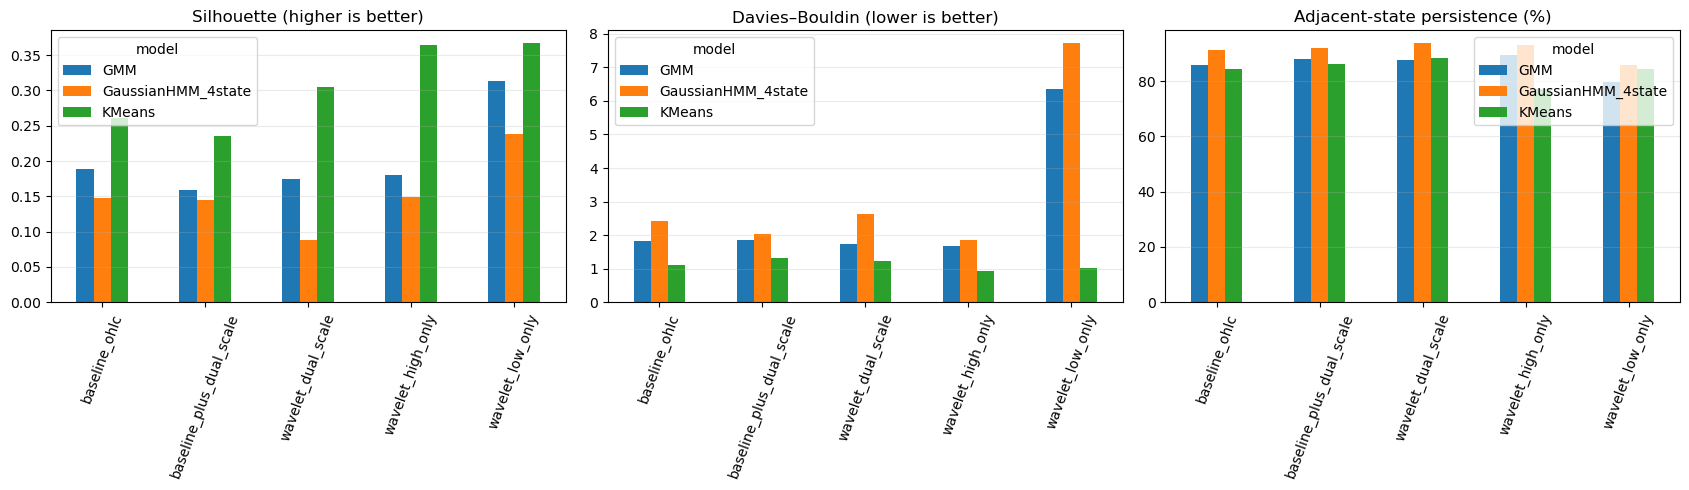

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, metric, title, ascending in [
    (axes[0], "silhouette", "Silhouette (higher is better)", False),
    (axes[1], "davies_bouldin", "Davies–Bouldin (lower is better)", True),
    (axes[2], "persistence_pct", "Adjacent-state persistence (%)", False)
]:
    pivot = comparison.pivot(index="feature_set", columns="model", values=metric)
    pivot.plot(kind="bar", ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=70)
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 10. Inspect HMM results and state occupancy

In [11]:
hmm_rows = comparison[comparison["model"] == "GaussianHMM_4state"].copy()
display(hmm_rows.sort_values("heldout_loglik_per_obs", ascending=False))

occupancy_rows = []
for (feature_name, model_name), states in state_outputs.items():
    if model_name == "GaussianHMM_4state":
        counts = pd.Series(states).value_counts(normalize=True).sort_index() * 100
        for state_id, pct in counts.items():
            occupancy_rows.append({
                "feature_set": feature_name,
                "state": int(state_id),
                "occupancy_pct": float(pct)
            })
occupancy_df = pd.DataFrame(occupancy_rows)
display(occupancy_df)
occupancy_df.to_csv(OUT_DIR / "dual_scale_hmm_state_occupancy.csv", index=False)

,feature_set,model,n_features,silhouette,davies_bouldin,calinski_harabasz,persistence_pct,heldout_loglik_per_obs,bic,fit_seconds,min_state_occupancy_pct,max_state_occupancy_pct
5,wavelet_low_only,GaussianHMM_4state,3,0.238548,7.716443,757.740933,85.942717,-2.243228,NaN,38.412656,6.465719,49.258160
8,wavelet_high_only,GaussianHMM_4state,5,0.149333,1.856738,1319.841233,93.076788,-2.633949,NaN,117.264300,2.514446,45.416211
2,baseline_ohlc,GaussianHMM_4state,6,0.147447,2.423388,739.402707,91.091197,-4.495422,NaN,81.929107,3.763861,34.811807
11,wavelet_dual_scale,GaussianHMM_4state,8,0.088206,2.620155,703.059699,93.656651,-5.461009,NaN,83.646493,1.983445,43.354677
14,baseline_plus_dual_scale,GaussianHMM_4state,14,0.145526,2.048439,875.251239,91.794061,-10.085351,NaN,54.109936,6.075277,47.071685


,feature_set,state,occupancy_pct
0,baseline_ohlc,0,3.763861
1,baseline_ohlc,1,34.811807
2,baseline_ohlc,2,33.031392
3,baseline_ohlc,3,28.392941
4,wavelet_low_only,0,49.258160
5,wavelet_low_only,1,26.190848
6,wavelet_low_only,2,6.465719
7,wavelet_low_only,3,18.085273
8,wavelet_high_only,0,34.358894
9,wavelet_high_only,1,45.416211


## 11. Causality and alignment checks

In [12]:
# Verify that the shared comparison index exactly matches both source feature tables
assert data.index.is_monotonic_increasing
assert data.index.is_unique
assert data.index.isin(baseline.index).all()
assert data.index.isin(wavelet.index).all()

# Confirm all test timestamps occur after all training timestamps.
assert train_all.index.max() < test_all.index.min()

# The wavelet source itself contains the prefix-causality result from Experiment 3.
wavelet_meta_path = WAVELET_DIR / "wavelet_experiment_metadata.json"
wavelet_meta = json.loads(wavelet_meta_path.read_text()) if wavelet_meta_path.exists() else {}
print("Experiment 3 causality check passed:",
      wavelet_meta.get("causality_check_passed", "metadata unavailable"))
print("Shared split is chronological:", train_all.index.max() < test_all.index.min())
print("Feature sets evaluated on identical shared timestamps:", len(data))

Experiment 3 causality check passed: True
Shared split is chronological: True
Feature sets evaluated on identical shared timestamps: 21340


## 12. Save experiment metadata and summary

In [13]:
summary = {
    "experiment": "Dual-scale temporal feature comparison",
    "dataset": "Bundled NIFTY 50 1-minute OHLC CSV files",
    "bar_interval": "15min",
    "chronological_split": "70/30",
    "total_aligned_rows": int(len(data)),
    "train_rows": int(len(train_all)),
    "test_rows": int(len(test_all)),
    "train_start": str(train_all.index.min()),
    "train_end": str(train_all.index.max()),
    "test_start": str(test_all.index.min()),
    "test_end": str(test_all.index.max()),
    "feature_sets": {name: cols for name, cols in feature_sets.items()},
    "models": ["KMeans_4", "GMM_4_diag", "GaussianHMM_4state"],
    "hmm_max_train_rows": MAX_HMM_TRAIN_ROWS,
    "hmm_max_test_rows": MAX_HMM_TEST_ROWS,
    "hmm_results": model_notes,
    "limitations": [
        "No independent ground-truth market regime labels are available.",
        "Internal clustering metrics are not supervised accuracy.",
        "HMM uses causal forward-filtered test state probabilities.",
        "HMM is evaluated on a capped contiguous train/test block; K-Means and GMM use the full shared partition.",
        "Feature-set results should be interpreted within each model family.",
        "No strategy profitability claim is made; transaction-cost-aware walk-forward testing remains necessary.",
        "Feature and model hyperparameters require sensitivity analysis."
    ]
}
(OUT_DIR / "dual_scale_experiment_metadata.json").write_text(json.dumps(summary, indent=2))
print("Saved outputs:")
for p in sorted(OUT_DIR.iterdir()):
    print(" -", p.name)

Saved outputs:
 - dual_scale_experiment_metadata.json
 - dual_scale_hmm_run_notes.csv
 - dual_scale_hmm_state_occupancy.csv
 - dual_scale_model_comparison.csv


## 13. How to interpret the results

Use these rules:

- If `wavelet_low_only` improves a model, the slower trend-like component may add useful structure.
- If `wavelet_high_only` improves it, short-term fluctuation/energy information may add useful structure.
- If `wavelet_dual_scale` beats both single branches, combining low and high scales may be beneficial.
- If `baseline_plus_dual_scale` improves on `baseline_ohlc`, wavelet features may add information beyond conventional OHLC indicators.
- For HMM, inspect held-out log-likelihood per observation, state occupancy, persistence and convergence together.
- Do not select a model only because its persistence is highest; a model stuck in one state can appear stable.
- A higher Silhouette score is not proof of better trading performance.

### Important fairness note
K-Means and GMM use the full shared train/test partition. HMM uses a capped contiguous block (up to 20,000 training and 10,000 test observations) for practical runtime. The HMM's internal metrics therefore use its own contiguous held-out block, not exactly the full K-Means/GMM test block. The metadata records these ranges. If a final head-to-head comparison is required, rerun all methods on the exact same capped timestamps.

### Next experiment
After reviewing these results, proceed to multi-timeframe analysis and then walk-forward validation with strategy returns, realistic transaction costs and slippage. Do not integrate a new model into the live MarketMind app yet.